# Exercise 65 – A Gaussian as the solution of first- and second-order ODEs

**Week 14 · Physics-informed neural networks**

The Gaussian $y = e^{-(x-1)^2/2\sigma^2}$ with $\sigma = 0.5$ solves both

$$\text{(1)}\quad y' = \frac{1-x}{\sigma^2}\,y \qquad\qquad
  \text{(2)}\quad y'^2 = y\,y'' + \frac{y^2}{\sigma^2}.$$

Equation (1) needs one condition, $y(1) = 1$. Equation (2) is second order,
so it needs two, e.g. $y(1) = 1$ and $y'(1) = 0$. We train PINNs on both and
plot the residual of equation (2) to see where the solution is accurate.

In [1]:
import matplotlib.pyplot as plt
import torch

from comphy.pinn import PINN, train_pinn
from comphy.plotting import setup_axes

torch.manual_seed(0)
SIGMA = 0.5


def gaussian(x):
    return torch.exp(-((x - 1) ** 2) / (2 * SIGMA**2))


def first_order(x, y, dy):
    return dy - (1 - x) / SIGMA**2 * y


def second_order(x, y, dy, d2y):
    return dy**2 - d2y * y - y**2 / SIGMA**2

## First-order equation, growing the training interval
The same network is trained on $[0, 2]$, then $[0, 5]$, then $[-5, 5]$
(3000 epochs each). A tiny network with one hidden layer of four neurons is
compared with a slightly larger one.

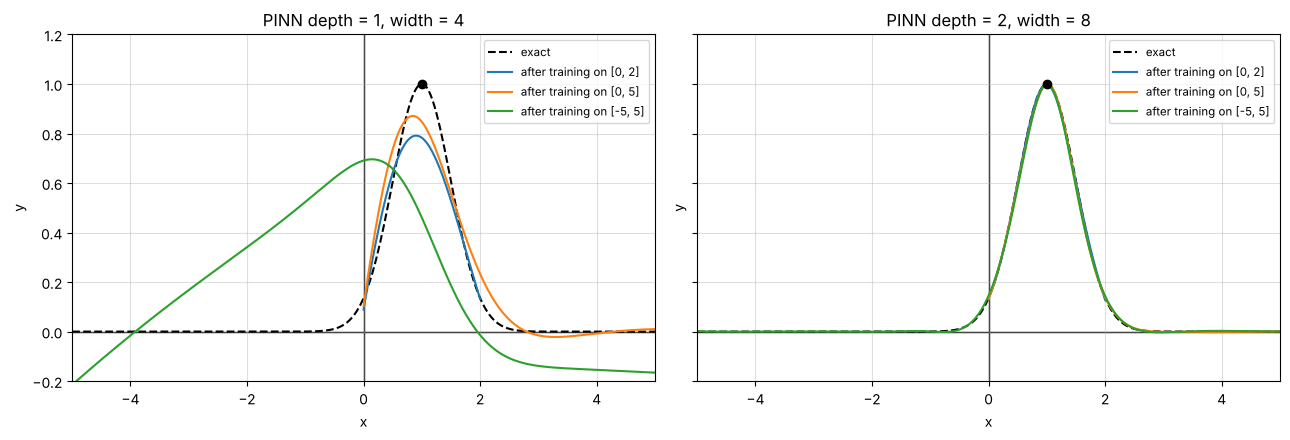

In [2]:
xs = torch.linspace(-5, 5, 300).view(-1, 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (depth, width) in zip(axes, [(1, 4), (2, 8)]):
    torch.manual_seed(0)
    model = PINN(depth=depth, width=width)
    ax.plot(xs, gaussian(xs), "k--", label="exact")
    for i, x_range in enumerate([(0, 2), (0, 5), (-5, 5)]):
        train_pinn(model, first_order, x_range=x_range, epochs=3000, values=[(1.0, 1.0)],
                   n_collocation=100)
        x_plot = torch.linspace(*x_range, 200).view(-1, 1)
        with torch.no_grad():
            ax.plot(x_plot, model(x_plot), color=f"C{i}", label=f"after training on {list(x_range)}")
    ax.scatter([1], [1], color="black", zorder=3)
    setup_axes(ax, xlim=(-5, 5), ylim=(-0.2, 1.2), title=f"PINN {model.describe()}")
    ax.legend(fontsize="small")
fig.tight_layout()
plt.show()

The small network cannot represent the Gaussian accurately over the whole
interval; with two hidden layers of eight neurons the PINN reproduces it
everywhere, also outside the region where it was first trained.

## Second-order equation with $y(1) = 1$, $y'(1) = 0$

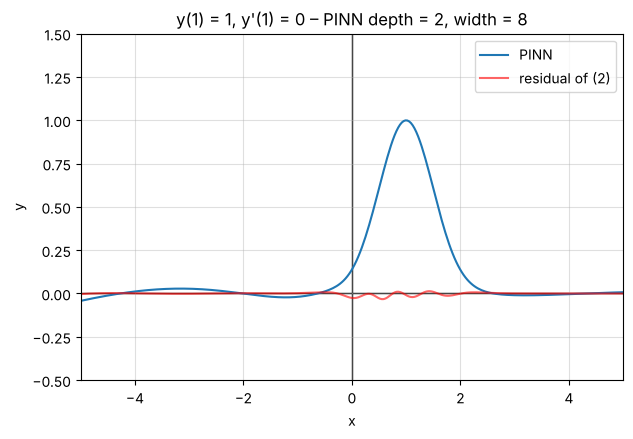

In [3]:
def plot_second_order(model, title, slopes=()):
    x = torch.linspace(-5, 5, 300).view(-1, 1).requires_grad_(True)
    y, dy, d2y = model.derivatives(x, order=2)
    res = second_order(x, y, dy, d2y)
    fig, ax = plt.subplots(figsize=(7, 4.5))
    with torch.no_grad():
        ax.plot(x.detach(), y, label="PINN")
        ax.plot(x.detach(), res, color="red", alpha=0.6, label="residual of (2)")
    for x_s, s in slopes:
        ax.plot([x_s - 0.25, x_s + 0.25], [-0.25 * s, 0.25 * s], color="green", lw=2)
    setup_axes(ax, xlim=(-5, 5), ylim=(-0.5, 1.5), title=title)
    ax.legend()
    plt.show()


torch.manual_seed(0)
model = PINN(depth=2, width=8)
train_pinn(model, second_order, x_range=(-5, 5), epochs=10_000, order=2,
           values=[(1.0, 1.0)], slopes=[(1.0, 0.0)])
plot_second_order(model, f"y(1) = 1, y'(1) = 0 – PINN {model.describe()}")

## Second-order equation with only slope conditions
What if we only prescribe alternating slopes $y'(x_k) = \pm 1$ at
$x_k = -4, \dots, 3$ (green segments)?

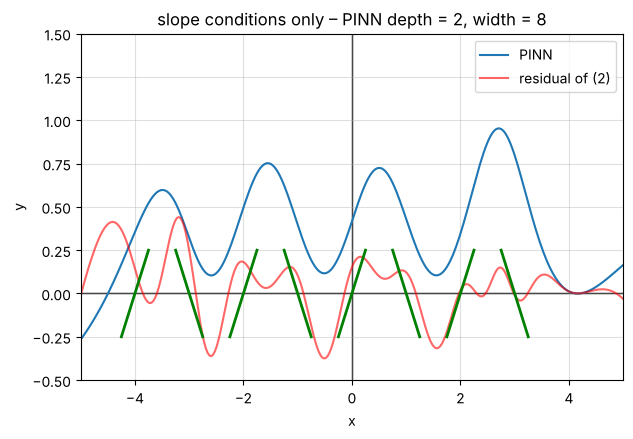

In [4]:
slopes = [(-4, 1), (-3, -1), (-2, 1), (-1, -1), (0, 1), (1, -1), (2, 1), (3, -1)]
torch.manual_seed(0)
model = PINN(depth=2, width=8)
train_pinn(model, second_order, x_range=(-5, 5), epochs=10_000, order=2, slopes=slopes)
plot_second_order(model, f"slope conditions only – PINN {model.describe()}", slopes=slopes)

The residual is now far from zero: the network cannot satisfy both the
equation and the conditions. This makes sense: with $u = \ln y$, equation (2)
becomes $u'' = -1/\sigma^2$, so *every* positive solution is a Gaussian of
width $\sigma$, and no Gaussian has alternating slopes. The PINN ends up with
a compromise that partly follows the slopes and partly the equation.